# Task 2: Exploration & Basic Statistics
**Dataset:** IMDB Dataset of 50K Movie Reviews (Kaggle, lakshmi25npathi)
**Member 1:** Maham Iqbal (L1F23BSCS0411)

This notebook explores the **raw, uncleaned** reviews. All the functions live in `src/data_analysis.py`, so the notebook and the script always give the same numbers.

> Run every cell from top to bottom: *Kernel → Restart & Run All*. Then take screenshots of the outputs for the report.

In [3]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Make the src/ folder importable (the notebook lives in notebook/)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import data_analysis as da
from load_data import load_raw

pd.set_option("display.max_colwidth", 200)
%matplotlib inline

## 1. Load the data and understand the columns

In [4]:
df = load_raw()
print(df.shape)
df.head()

(14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials to the experience... tacky.,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I need to take another trip!,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing about it,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  str    
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   str    
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  str    
 6   airline_sentiment_gold        40 non-null     str    
 7   name                          14640 non-null  str    
 8   negativereason_gold           32 non-null     str    
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  str    
 11  tweet_coord                   1019 non-null   str    
 12  tweet_created                 14640 non-null  str    
 13  tweet_locati

In [6]:
info = da.basic_info(df)
info

{'n_rows': 14640,
 'n_columns': 15,
 'columns': ['tweet_id',
  'airline_sentiment',
  'airline_sentiment_confidence',
  'negativereason',
  'negativereason_confidence',
  'airline',
  'airline_sentiment_gold',
  'name',
  'negativereason_gold',
  'retweet_count',
  'text',
  'tweet_coord',
  'tweet_created',
  'tweet_location',
  'user_timezone'],
 'missing_values': {'tweet_id': 0,
  'airline_sentiment': 0,
  'airline_sentiment_confidence': 0,
  'negativereason': 5462,
  'negativereason_confidence': 4118,
  'airline': 0,
  'airline_sentiment_gold': 14600,
  'name': 0,
  'negativereason_gold': 14608,
  'retweet_count': 0,
  'text': 0,
  'tweet_coord': 13621,
  'tweet_created': 0,
  'tweet_location': 4733,
  'user_timezone': 4820},
 'n_duplicate_rows': 36,
 'n_duplicate_tweet_ids': 155,
 'n_duplicate_texts': 213,
 'n_unique_texts': 14427}

**Columns:**
- `review`: the raw review text (contains HTML tags like `<br />`)
- `sentiment`: the label, `positive` or `negative`, which is our **prediction target**

**Duplicates:** some reviews appear more than once. We report them here; the cleaning pipeline (Member 5) removes them.

In [10]:

# Look at a few duplicated tweets
dups = df[df.duplicated(keep=False)].sort_values("text")
print("Duplicate rows (excluding first occurrence):", df.duplicated().sum())
dups.head(6)

Duplicate rows (excluding first occurrence): 36


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
11902,570303383782989824,neutral,1.0,NaN,NaN,American,NaN,trentgillaspie,NaN,0,.@AmericanAir just disappointed with the Flight Booking Problems process and add’l fees to sit together on a more crowded flight. Not impressed so far :-/.,NaN,2015-02-24 11:24:57 -0800,"Austin, but often Denver",Mountain Time (US & Canada)
12063,570303383782989824,neutral,1.0,NaN,NaN,American,NaN,trentgillaspie,NaN,0,.@AmericanAir just disappointed with the Flight Booking Problems process and add’l fees to sit together on a more crowded flight. Not impressed so far :-/.,NaN,2015-02-24 11:24:57 -0800,"Austin, but often Denver",Mountain Time (US & Canada)
12134,570279653337927680,positive,1.0,NaN,NaN,American,NaN,sundialtours,NaN,0,"@AmericanAir ""Airport snow removal method #22...""\nKeep up the good work folks, this is where Cessna's become 747's! http://t.co/oUmC1LrXDN",NaN,2015-02-24 09:50:39 -0800,"Astoria, OR",Tijuana
11973,570279653337927680,positive,1.0,NaN,NaN,American,NaN,sundialtours,NaN,0,"@AmericanAir ""Airport snow removal method #22...""\nKeep up the good work folks, this is where Cessna's become 747's! http://t.co/oUmC1LrXDN",NaN,2015-02-24 09:50:39 -0800,"Astoria, OR",Tijuana
11944,570289085354541058,negative,1.0,Lost Luggage,1.0,American,NaN,brownsrock,NaN,0,@AmericanAir - Please find my bag!! In Singapore for three days already without my bag. Last known destination LAX Tag: 580815 Please help.,NaN,2015-02-24 10:28:08 -0800,"Bangkok, Thailand",Bangkok
12105,570289085354541058,negative,1.0,Lost Luggage,1.0,American,NaN,brownsrock,NaN,0,@AmericanAir - Please find my bag!! In Singapore for three days already without my bag. Last known destination LAX Tag: 580815 Please help.,NaN,2015-02-24 10:28:08 -0800,"Bangkok, Thailand",Bangkok


## 2. Number of documents & average length (in words)

In [11]:
lengths = da.doc_lengths(df)
print("Number of documents:", len(df))
da.length_stats(lengths)

Number of documents: 14640


{'mean_words': 17.65,
 'median_words': 19.0,
 'std_words': 6.88,
 'min_words': 2,
 'max_words': 36}

TypeError: object of type 'WindowsPath' has no len()

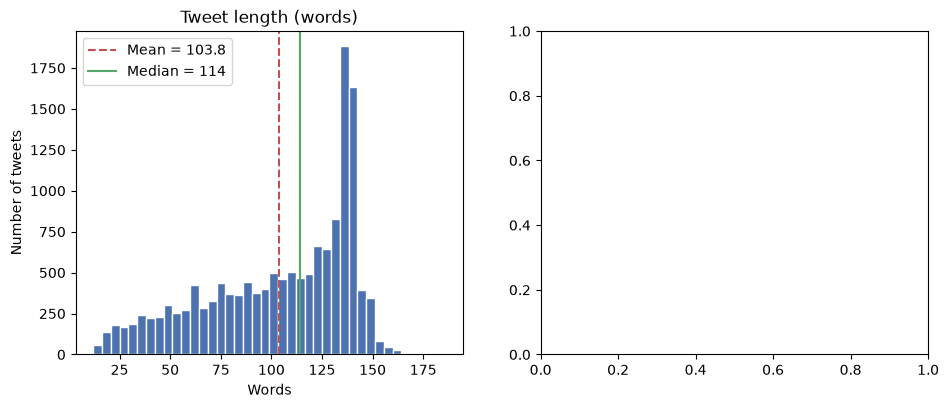

In [13]:
# Calculate lengths using the correct 'text' column for the Twitter dataset
lengths = df['text'].astype(str).str.len()

# Now plot the length distribution
da.plot_length_hist(lengths, da.FIG_DIR / "length_distribution.png")
plt.show()

## 3. Target distribution

In [ ]:
da.target_distribution(df)

In [ ]:
da.plot_target(df, da.FIG_DIR / "target_distribution.png")
plt.show()

## 4. Vocabulary size (whole corpus)
Tokenizer: lowercase + regex `\w+` (`da.simple_tokenize`). This is the **baseline before cleaning**. Member 4 should use the same function for the "before" vocabulary count.

In [ ]:
print(da.simple_tokenize("This movie was GREAT!!<br /><br />I didn't expect it."))

In [ ]:
counter = da.word_counts(df["review"])
da.vocab_stats(counter)

## 5. Tokens vs types on a random sample (1000 reviews, `random_state=42`)

In [ ]:
da.sample_tokens_types(df)

In [ ]:
growth = da.type_growth(df)
da.plot_type_growth(growth, da.FIG_DIR / "type_growth.png")
plt.show()

## 6. Zipf's law and the long tail
**Zipf's law:** the frequency of a word is roughly inversely proportional to its rank (f ∝ 1/rank). On a log-log plot, this shows up as a roughly straight line sloping downwards.

In [ ]:
pd.DataFrame(counter.most_common(20), columns=["word", "frequency"]).rename_axis("rank").rename(index=lambda i: i + 1)

In [ ]:
da.plot_zipf(counter, da.FIG_DIR / "zipf_plot.png")
plt.show()

In [ ]:
da.plot_top_words(counter, 20, da.FIG_DIR / "top20_words.png")
plt.show()

In [ ]:
v = da.vocab_stats(counter)
print(f"Words that appear only ONCE (hapax legomena): {v['hapax_legomena']:,} "
      f"= {v['hapax_percent_of_vocab']}% of the vocabulary")
print(f"The top 100 words cover {v['top100_words_percent_of_tokens']}% of all tokens")

## 7. Messy text examples

In [ ]:
messy = da.find_messy_examples(df)
messy[["issue", "reviews_affected", "percent_of_reviews", "example_row", "matched_text"]]

In [ ]:
# Print the snippet for each issue (pick 3-5 of these for the report)
for _, r in messy.iterrows():
    if r["reviews_affected"]:
        print(f"### {r['issue']} | row {int(r['example_row'])} | {df.at[int(r['example_row']), 'sentiment']}")
        print(r["snippet"], "\n")

In [ ]:
# Look at any full review by its row number
row = int(messy.loc[0, "example_row"])
print(df.at[row, "review"])

## 8. Save everything for the report

In [ ]:
da.main()   # re-runs the full analysis and writes report/figures, report/stats.json, report/messy_examples.txt

## Observations (write these in your own words after running)
- **Size & duplicates:** ...
- **Length:** ... (note: whitespace word counts include HTML fragments like `<br`)
- **Target:** ... (balanced? why that matters for Phase 2)
- **Vocabulary / tokens vs types:** ...
- **Zipf & long tail:** ... (is it close to a straight line? which words are at the top? why does `br` appear?)
- **Messy text:** ... (which issues need cleaning, and which might carry sentiment, e.g. ALL CAPS, `!!!`)